[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simon-clematide/gemma-qlora-finetuning/blob/main/notebooks/11_colab_l4_live_demo.ipynb)

# Instruction Fine-Tuning in Practice: From Zero-Shot Predictions to Task-Specific Classification
*An end-to-end Gemma-2-2B experiment using QLoRA and GermEval 2017.*

---
# Part I — Experimental Design and Setup

## 1. Research Question and Experimental Design

### Research Question
> **Can supervised instruction fine-tuning teach a general-purpose language model to produce more accurate and reliably structured predictions for a specialized classification task?**

$$
\boxed{\text{Task} \rightarrow \text{Instructions} \rightarrow \text{Training examples} \rightarrow \text{Optimization} \rightarrow \text{Changed predictions} \rightarrow \text{Measured improvement}}
$$

### The Prediction Task (GermEval 2017 Task C)
Given a German customer-feedback text about rail travel (*Deutsche Bahn*), the model must identify all expressed aspect categories from a fixed ontology of **19 permitted categories** and assign a sentiment polarity (`positive`, `neutral`, or `negative`) to each—or return an empty list `{"labels": []}` when the document is not relevant customer feedback.

For example, consider the illustrative input:
> *Der Zug war pünktlich, aber das Personal war unfreundlich.*

Using the dataset's permitted ontology, the expected structured output is:
```json
{
  "labels": [
    "Zugfahrt:positive",
    "Service_und_Kundenbetreuung:negative"
  ]
}
```

### Experimental Comparison
We compare two systems under identical evaluation conditions:
- **Baseline (Zero-shot):** Pretrained `google/gemma-2-2b-it` using task instructions and category definitions (`p1_guidelines`) without task-specific parameter updates.
- **Fine-tuned (Supervised Adapter):** The same base model with a low-rank adapter trained on labeled GermEval 2017 examples using the identical instruction template.

Both systems receive the same evaluation inputs and must emit the same JSON schema.

### Hypothesis
Supervised instruction fine-tuning should improve task-specific classification performance (Category and Category+Sentiment F1) and improve adherence to the required JSON output format.

### Learning Objectives
After working through this notebook, you should be able to:
1. Explain the difference between zero-shot inference and supervised instruction fine-tuning.
2. Describe how labeled dataset examples are converted into instruction–completion pairs.
3. Explain why completion-only loss masking is used and how it relates to attention and gradient propagation.
4. Distinguish instruction fine-tuning (the learning objective) from LoRA and QLoRA (the parameter- and memory-efficiency mechanisms).
5. Evaluate improvements in classification accuracy and output validity using paired bootstrap confidence intervals.
6. Recognize the limitations of conclusions drawn from small-scale classroom experiments.

---
## 2. Environment and Model Setup

- **Concept:** A reproducible experiment requires deterministic data preparation, recorded hardware/software state, and verified artifact provenance. This notebook supports two clearly labeled execution modes:
  - **`LIVE` — Classroom Experiment (CUDA GPU):** On a supported CUDA GPU (Google Colab **L4** or **T4**), trains a new adapter and generates fresh predictions.
  - **`REPLAY` — Recorded Experiment (No GPU required):** Loads a complete, internally consistent recording (`classroom_fast_n1000_seed42`) of the classroom experiment—including its manifest, training history, and real `google/gemma-2-2b-it` zero-shot and fine-tuned predictions on the same evaluation split.
- **Implementation:** Initialize the repository, materialize the derived JSONL splits from the canonical archives, and detect available compute hardware.

In [1]:
import importlib, json, os, subprocess, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if 'google.colab' in sys.modules:
    REPO_URL = os.environ.get('GERMEVAL_REPO_URL', 'https://github.com/simon-clematide/gemma-qlora-finetuning.git')
    if not Path('pyproject.toml').exists() and not Path('gemma-qlora-finetuning/pyproject.toml').exists():
        subprocess.run(['git', 'clone', '-q', REPO_URL], check=True)
    if Path('gemma-qlora-finetuning/pyproject.toml').exists():
        os.chdir('gemma-qlora-finetuning')
    subprocess.run(['git', 'fetch', '-q', 'origin', 'main'], check=True)
    subprocess.run(['git', 'reset', '-q', '--hard', 'origin/main'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'bitsandbytes>=0.46.1', '-e', '.[ml,cuda]'], check=True)

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
    os.chdir(ROOT)
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

# Evict any cached germeval_llm modules from prior runs in a warm Colab/Jupyter kernel
for _mod in [k for k in list(sys.modules) if k == 'germeval_llm' or k.startswith('germeval_llm.')]:
    sys.modules.pop(_mod, None)

from germeval_llm.convert import ensure_derived_datasets_ready
from germeval_llm.inference import detect_compute_device

ensure_derived_datasets_ready()
hw = detect_compute_device()
RUN_LIVE_GPU = bool(hw['cuda_available'])
EXECUTION_MODE = 'LIVE (Classroom GPU Run)' if RUN_LIVE_GPU else 'REPLAY (Recorded Classroom Experiment)'
git_rev = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
dev_label = f"{hw['gpu_name']} ({hw['gpu_vram_gb']} GB VRAM)" if hw['cuda_available'] else f"{hw['device'].upper()} (No CUDA GPU -> Replay mode)"

print('ENVIRONMENT SUMMARY')
print('─' * 52)
print(f'Repository commit:   {git_rev}')
print(f'Execution mode:      {EXECUTION_MODE}')
print(f'Compute device:      {dev_label}')
print(f'PyTorch version:     {hw.get("torch_version", "N/A")} (bf16_supported={hw["bf16_supported"]})')
print(f'Canonical dataset:   Ready (train / dev / test_syn / test_dia)')

ENVIRONMENT SUMMARY
────────────────────────────────────────────────────
Repository commit:   c84e69b
Execution mode:      REPLAY (Recorded Classroom Experiment)
Compute device:      MPS (No CUDA GPU -> Replay mode)
PyTorch version:     2.14.1 (bf16_supported=True)
Canonical dataset:   Ready (train / dev / test_syn / test_dia)


### Model Access and Authentication
`google/gemma-2-2b-it` is a gated model on the Hugging Face Hub: downloading its weights in **LIVE** mode requires accepting the Gemma license on Hugging Face and providing an access token. In **REPLAY** mode, recorded experiment artifacts are loaded from the repository so no token is needed.

In [2]:
if RUN_LIVE_GPU:
    from huggingface_hub import login
    os.environ.pop('HF_TOKEN', None)
    os.environ.pop('HUGGING_FACE_HUB_TOKEN', None)
    try:
        login(skip_if_logged_in=False)
    except TypeError:
        login(new_session=True)
else:
    print('REPLAY mode active: using recorded experiment artifacts (Hugging Face login skipped).')

REPLAY mode active: using recorded experiment artifacts (Hugging Face login skipped).


### Pre-Flight Verification Suite (T4 / L4 / Replay)
Before starting baseline inference or fine-tuning, we run a fast (~2–5 second) **8-point pre-flight diagnostic** (`run_preflight_diagnostics`) that tests every assumption made by the rest of the notebook on the active hardware:
1. **Module freshness & symbols** (`germeval_llm.*` synced from disk, no stale `sys.modules` cache)
2. **Data splits, manifests & `doc_id` alignment**
3. **Prompt rendering & completion-only loss masking (`-100`)**
4. **Hardware & dtype policy** (`T4 CC 7.5`: `float16` 4-bit/LoRA Tensor Core compute, `sdpa` attention, `grad_ckpt=False`; `L4 CC 8.9`: native `bfloat16`)
5. **4-bit `NF4` quantization (`bitsandbytes`)** on a micro `Gemma2ForCausalLM`
6. **`SFTTrainer` + `PEFT` 2-step train & validation loop** (`completion_only_loss=True`, `prediction_loss_only=True`, `paged_adamw_8bit`)
7. **Adapter save/reload (`PeftModel`) & greedy `model.generate`**
8. **Gated Hugging Face access (`google/gemma-2-2b-it`), paired bootstrap & plotting**

In [3]:
from germeval_llm.training import run_preflight_diagnostics

preflight = run_preflight_diagnostics(
    check_hf_gated_access=RUN_LIVE_GPU,
    use_4bit_quantization=True,
)
print(f'PRE-FLIGHT VERIFICATION PASSED ({preflight["elapsed_sec"]}s on {preflight["device"].upper()})')
display(pd.DataFrame(preflight['checks']))

W1018 04:19:06.669000 89658 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/24 [00:00<?, ?it/s]

Adding EOS to train dataset:   0%|          | 0/4 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/4 [00:00<?, ? examples/s]

...

/Users/siclemat/pj/2026/gemma-qlora-finetuning/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,5.536762,5.510297,5.534003,0.000000,20.000000
2,5.510297,5.497065,5.534047,0.000000,40.000000


Loading weights:   0%|          | 0/24 [00:00<?, ?it/s]

PRE-FLIGHT VERIFICATION PASSED (2.04s on MPS)


,Check,Status,Details
0,1. Module Freshness & Symbols,PASS,All 12 required functions present
1,2. Data & Manifest Alignment,PASS,Verified 150 aligned test_syn docs & manifest ...
2,3. Prompt & Loss Masking (-100),PASS,"total=867, masked=857, active=10"
3,4. Hardware & Precision Policy,PASS,"Device=MPS (bf16=True, dtype=torch.bfloat16)"
4,5. Quantization & Model Load,PASS,"Loaded micro Gemma2 (load_in_4bit=False, Param..."
5,6. SFTTrainer Train + Eval Loop,PASS,"2 steps + eval_loss=5.4971, train_loss=5.5235,..."
6,7. Adapter Reload & Generation,PASS,PeftModel reloaded & generated 6 tokens cleanl...
7,"8. HF Access, Eval & Plotting",PASS,Skipped (REPLAY mode); ΔF1(C2)=+0.4317; 5 arch...


---
# Part II — Task, Training Instructions, and Baseline

## 3. Understanding the Task and Dataset

- **Concept:** In a supervised machine learning experiment, data splits serve distinct methodological roles:
  - **Training set (`train`):** Labeled examples used to optimize the model's adapter parameters.
  - **Development / validation set (`dev`):** Held-out examples used to monitor validation loss during training and make modeling decisions without peeking at the test set.
  - **Held-out synchronic test set (`test_syn`):** Unseen examples from the same time period used strictly to measure the before/after effect of fine-tuning.
  - **Held-out diachronic test set (`test_dia`):** Examples collected six months later to test robustness to temporal topic drift.
- **Implementation:** Load the canonical splits and inspect representative examples spanning multi-aspect feedback, single-aspect feedback, and irrelevant documents (`relevance=false`).

In [4]:
from germeval_llm.xml_parser import load_canonical_jsonl
from germeval_llm.convert import extract_task_c_label_sets

train_docs = load_canonical_jsonl('data/canonical/train.jsonl')
dev_docs = load_canonical_jsonl('data/canonical/dev.jsonl')
test_syn_docs = load_canonical_jsonl('data/canonical/test_syn.jsonl')
test_dia_docs = load_canonical_jsonl('data/canonical/test_dia.jsonl')

split_rows = []
for name, role, docs in [
    ('train', 'Parameter optimization (supervised learning)', train_docs),
    ('dev', 'Validation monitoring & model selection', dev_docs),
    ('test_syn', 'Held-out evaluation (same time period)', test_syn_docs),
    ('test_dia', 'Held-out evaluation (6 months later)', test_dia_docs),
]:
    rel_rate = sum(1 for d in docs if d.relevance) / len(docs)
    avg_ops = sum(len(d.opinions) for d in docs) / len(docs)
    split_rows.append({
        'Split': name,
        'Methodological Role': role,
        'Documents': f'{len(docs):,}',
        'Relevant (%)': f'{100 * rel_rate:.1f}%',
        'Mean Opinions / Doc': f'{avg_ops:.2f}',
    })
display(pd.DataFrame(split_rows))

# Select 3 representative training examples: multi-aspect, single-aspect, and irrelevant
rep_multi = next(d for d in train_docs if len(extract_task_c_label_sets(d, True)[0]) >= 2)
rep_single = next(d for d in train_docs if len(extract_task_c_label_sets(d, True)[0]) == 1)
rep_irrel = next(d for d in train_docs if not d.relevance and len(d.opinions) == 0)

sample_table = []
for kind, d in [
    ('Multi-aspect feedback', rep_multi),
    ('Single-aspect feedback', rep_single),
    ('Out-of-scope / irrelevant', rep_irrel),
]:
    gold_c2, _ = extract_task_c_label_sets(d, apply_typo_patches=True)
    sample_table.append({
        'Example Type': kind,
        'Relevant?': d.relevance,
        'German Input Text': d.text[:120] + ('...' if len(d.text) > 120 else ''),
        'Gold Task C2 Labels': json.dumps({'labels': gold_c2}, ensure_ascii=False),
    })
print('\nRepresentative Training Examples:')
display(pd.DataFrame(sample_table))

,Split,Methodological Role,Documents,Relevant (%),Mean Opinions / Doc
0,train,Parameter optimization (supervised learning),"19,432",83.4%,1.11
1,dev,Validation monitoring & model selection,"2,369",81.5%,1.06
2,test_syn,Held-out evaluation (same time period),"2,566",81.6%,1.27
3,test_dia,Held-out evaluation (6 months later),"1,842",84.0%,1.13



Representative Training Examples:


,Example Type,Relevant?,German Input Text,Gold Task C2 Labels
0,Multi-aspect feedback,True,"Re: Interessengemeinschaft Bahn ""Die DB ist we...","{""labels"": [""Allgemein:negative"", ""DB_App_und_..."
1,Single-aspect feedback,True,Bahn: Streik endet vorzeitig Der Streik der Ge...,"{""labels"": [""Allgemein:positive""]}"
2,Out-of-scope / irrelevant,False,Nike Free Run 3.0 V2 Damen 4357RV | dzwiannerx...,"{""labels"": []}"


- **Observation & Interpretation:** Notice that roughly one-third of the corpus consists of irrelevant or non-feedback posts where the correct output is `{"labels": []}`, while relevant documents can express multiple categories with distinct polarities in a single sentence.

---
## 4. From Examples to Training Instructions

- **Concept:** How does a causal language model learn from a labeled classification example? We convert each annotated document through **three representations**:
  1. **A. Original dataset representation:** The document text and its gold-standard `<Opinion>` annotations.
  2. **B. Instruction–completion representation:** A chat prompt containing the task instructions, the 19 category definitions, and the input text (`user` turn), paired with the target JSON string (`model` turn).
  3. **C. Token-level training representation (Completion-only loss masking):**

| Sequence Component | Example | Training Loss (`labels`) | Role in Prediction and Loss Computation |
| :--- | :--- | :---: | :--- |
| **Instruction** | `Du bist ein Experte für die...` | **Ignored (`-100`)** | Available as conditioning context; excluded as direct prediction targets. |
| **Input** | `Text:\nDer Zug war pünktlich …` | **Ignored (`-100`)** | Available as conditioning context; excluded as direct prediction targets. |
| **Assistant delimiter** | `<start_of_turn>model\n` | **Ignored (`-100`)** | Available as conditioning context; excluded as direct prediction targets. |
| **Completion** | `{"labels": ["..."]}<end_of_turn>\n` | **Computed (`token_id`)** | Prediction targets contributing directly to cross-entropy loss. |

```text
Token Stream:   <bos> <start_of_turn>user\n ... [Prompt & Input Tokens] ... <start_of_turn>model\n {"labels": ["..."]} <end_of_turn>\n
Target Labels:  -100         -100                        -100                         -100         "{"  "labels" ... "]}" <end_of_turn>
                  └───────────────────────────────────────┬──────────────────────────────────────┘ └───┬───────────────────────────┘
                                     CONDITIONING CONTEXT (label = -100)                         DIRECT PREDICTION TARGETS
                                    (Excluded from Cross-Entropy Loss Sum)                      (Contribute to Cross-Entropy Loss)
```

**Important distinction:**
- **Loss masking:** Setting `label = -100` tells PyTorch's cross-entropy loss to compute no loss term for predicting the prompt tokens themselves.
- **Attention:** Causal self-attention still allows every completion token to attend to the full instruction and input document.
- **Gradient propagation:** Trainable adapter parameters involved in encoding the prompt still receive gradients through their contribution to predicting the unmasked completion tokens.

- **Implementation:** Inspect all three representations and run token-level loss masking on a real training example.

In [5]:
import html, importlib
from IPython.display import HTML
import germeval_llm.prompts as _prompts_mod
if not hasattr(_prompts_mod, 'inspect_completion_only_masking'):
    if 'google.colab' in sys.modules:
        subprocess.run(['git', 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', 'reset', '-q', '--hard', 'origin/main'], check=True)
    for _m in [k for k in list(sys.modules) if k == 'germeval_llm' or k.startswith('germeval_llm.')]:
        sys.modules.pop(_m, None)
from germeval_llm.schemas import TaskCExample
from germeval_llm.prompts import (
    format_gemma_chat_string,
    inspect_completion_only_masking,
    render_task_c_user_prompt,
)

# Find the derived TaskCExample corresponding to our multi-aspect training document
with Path('data/derived/task_c/train.jsonl').open(encoding='utf-8') as f:
    derived_train = [TaskCExample.model_validate_json(line) for line in f if line.strip()]
sample_ex = next(ex for ex in derived_train if ex.doc_id == rep_multi.doc_id)

# Dynamically generate the rendered prompt and Gemma chat string from the prompt-building functions
rendered_user_prompt = render_task_c_user_prompt(sample_ex.text, prompt_key='p1_guidelines')
full_prompt_turn = format_gemma_chat_string(sample_ex.prompt, completion_messages=None, include_bos=True)
full_training_sequence_str = format_gemma_chat_string(
    sample_ex.prompt, completion_messages=sample_ex.completion, include_bos=True
)
pretty_completion_json = json.dumps(
    json.loads(sample_ex.completion[0].content), ensure_ascii=False, indent=2
)

print('A. ORIGINAL DATASET REPRESENTATION')
print('─' * 68)
print(f'Document ID:   {rep_multi.doc_id}')
print(f'Input Text:    {rep_multi.text}')
print('Gold Opinions:')
for op in rep_multi.opinions:
    print(f'  • category={op.category!r}, polarity={op.polarity!r}, target={op.target_xml!r}')

print('\nB. INSTRUCTION–COMPLETION PAIR (Compact View with Gemma Chat-Template Boundaries)')
print('─' * 68)
prompt_lines = rendered_user_prompt.splitlines()
# Locate the taxonomy section (19 category lines) to show a compact view in the main flow
tax_idx = next(i for i, ln in enumerate(prompt_lines) if ln.startswith('Taxonomie der 19'))
pol_idx = next(i for i, ln in enumerate(prompt_lines) if ln.startswith('Erlaubte Polaritäten:'))
compact_prompt_lines = (
    ['<bos><start_of_turn>user']
    + prompt_lines[: tax_idx + 3]
    + [f'  ... [{(pol_idx - 1) - (tax_idx + 3)} additional category definitions omitted in compact view; expand full prompt below] ...']
    + prompt_lines[pol_idx - 2 :]
    + ['<end_of_turn>', '<start_of_turn>model']
)
print('1. The input sent to the model (conditioning context, masked with label = -100):\n')
print('\n'.join(compact_prompt_lines))
print('\n2. The expected completion (supervised prediction target, active in cross-entropy loss):\n')
print(pretty_completion_json)
print('<end_of_turn>')
print(f'\n   (Serialized single-line target in JSONL: {sample_ex.completion[0].content}<end_of_turn>)')

# Display the complete, unabridged rendered prompt (~600 tokens) in an expandable block
details_html = f'''
<details style="margin: 10px 0; padding: 8px 12px; border: 1px solid #cbd5e1; border-radius: 6px; background: #f8fafc;">
  <summary style="cursor: pointer; font-weight: 600; color: #1e293b;">
    🔍 Expand to inspect the complete, unabridged rendered training sequence (full P1_guidelines prompt + target completion)
  </summary>
  <pre style="margin-top: 8px; white-space: pre-wrap; font-size: 12px; line-height: 1.4; color: #0f172a;">{html.escape(full_training_sequence_str)}</pre>
</details>
'''
display(HTML(details_html))

mask_diag = inspect_completion_only_masking(sample_ex, context_window_before_turn=4)
print('\nC. TOKENIZED TRAINING SEQUENCE & LOSS MASKING DIAGNOSTIC')
print('─' * 68)
print(f'Total sequence tokens:       {mask_diag["total_tokens"]:4d}')
print(f'Instruction/input tokens:    {mask_diag["masked_prompt_tokens"]:4d}  (masked: label = -100)')
print(f'Completion tokens:           {mask_diag["active_completion_tokens"]:4d}')
print(f'Tokens contributing to loss: {mask_diag["active_completion_tokens"]:4d}  ({mask_diag["active_percentage"]}% of sequence)')

print('\nToken Boundary Around <start_of_turn>model\\n:')
display(pd.DataFrame(mask_diag['boundary_preview']))

A. ORIGINAL DATASET REPRESENTATION
────────────────────────────────────────────────────────────────────
Document ID:   http://www.facebook.com/198231213653920/posts/825424197601282?comment\_id=825562477587454#198231213653920\_825424197601282\_825562477587454
Input Text:    Re: Interessengemeinschaft Bahn "Die DB ist weit weg davon, es ""recht"" zu tun. Und andere Beteiligte wie BOB/Meridian oder gar die BEG bekleckern sich auch nicht mit Ruhm. Ob man bei den Gegebenheiten die Baustelle hätte kundenfreundlicher abwickeln können, kann ich nicht beurteilen. Jede Art von Vertrauensvorschuss bei solchen Themen hat die DB allerdings schon lange verspielt. Dass jedoch die Kundeninformation bzgl. geänderter Fahrpläne, die Fahrplanaktualisierung in den Online-Auskunftssystemen usw., in diesem Ausmaß daneben ist, das ist einfach nicht normal."
Gold Opinions:
  • category='Allgemein', polarity='negative', target='weit weg davon * recht * zu tun'
  • category='Allgemein', polarity='negative', targ


C. TOKENIZED TRAINING SEQUENCE & LOSS MASKING DIAGNOSTIC
────────────────────────────────────────────────────────────────────
Total sequence tokens:        953
Instruction/input tokens:     929  (masked: label = -100)
Completion tokens:             24
Tokens contributing to loss:   24  (2.52% of sequence)

Token Boundary Around <start_of_turn>model\n:


,position,token,input_id,label,role_in_loss
0,925,'\n',108,-100,Ignored (-100: conditioning context)
1,926,'<start_of_turn>',106,-100,Ignored (-100: conditioning context)
2,927,'model',2516,-100,Ignored (-100: conditioning context)
3,928,'\n',108,-100,Ignored (-100: conditioning context)
4,929,"'{""'",9766,9766,Computed (direct completion target)
5,930,'labels',12488,12488,Computed (direct completion target)
6,931,"'"":[""'",199831,199831,Computed (direct completion target)
7,932,'Allgeme',107217,107217,Computed (direct completion target)
8,933,'in',473,473,Computed (direct completion target)
9,934,':',235292,235292,Computed (direct completion target)


- **Observation & Interpretation:** The prompt (`<bos><start_of_turn>user ... <end_of_turn>\n<start_of_turn>model\n`) provides the task instructions, permitted taxonomy labels, and input document as **conditioning context**, while the JSON completion supplies the **supervised target**. Out of ~950 tokens in the training sequence, only the 24 tokens after `<start_of_turn>model\n` (~2.5% of the sequence) are direct prediction targets (`label != -100`). In **Section 10**, we will inspect this exact same prompt structure on a held-out evaluation example to see how the model's generated completion changes after fine-tuning.

### Design Note: Why Use a German Prompt (with English Polarity Tags) for Gemma 2?
Even though `google/gemma-2-2b-it` was pretrained predominantly on English, keeping the `p1_guidelines` prompt in German (paired with the official English polarity values `positive`, `neutral`, `negative`) is a deliberate design choice for three reasons:
1. **Lexical Alignment with the Label Taxonomy:** The 19 official GermEval 2017 aspect categories are German compound nouns (`Zugfahrt`, `Sonstige_Unregelmäßigkeiten`, `Service_und_Kundenbetreuung`, `Gepäck_Aufbewahrung`) whose boundaries depend on domain-specific German distinctions (e.g., *Verspätung/Ausfall* $\rightarrow$ `Sonstige_Unregelmäßigkeiten` vs. general ride mentions $\rightarrow$ `Zugfahrt`). Defining the guidelines in German anchors the model directly in the exact label strings it must emit, whereas English meta-prompts frequently cause smaller (2B) zero-shot models to translate or hallucinate English category names (such as `"Train_ride:negative"` or `"Customer_service:negative"`).
2. **Gemma 2's 256k SentencePiece Vocabulary:** Unlike older 32k English-centric tokenizers that fragment German compounds into byte-level pieces, Gemma 2's 256,000-token multilingual vocabulary provides strong whole-word and sub-compound coverage of German.
3. **Zero-Shot vs. Supervised Fine-Tuning:** In zero-shot mode, `gemma-2-2b-it` has less German instruction-following exposure than English, which contributes to its lower initial JSON formatting compliance (`~18%` exact JSON) and boundary errors. Once fine-tuned with completion-only loss masking, however, the German prompt acts as a consistent conditioning prefix that the adapter rapidly maps to valid `Category:polarity` JSON completions (`100%` valid JSON).

---
## 5. Zero-Shot Baseline

- **Concept:** Before training an adapter, we measure how well the frozen base model (`google/gemma-2-2b-it`) performs using the task instructions alone. When loading stored baseline predictions (`RECOMPUTE_ZERO_SHOT_BASELINE = False`), we verify the **experiment manifest** and align predictions by `doc_id` (`align_predictions`) to guarantee that the baseline and fine-tuned systems are evaluated on the exact same documents under the same prompt.
- **Implementation:** Configure the experiment scope (`fast_l4` classroom run on 150 `test_syn` documents vs. `full_l4` full benchmark), verify `doc_id` alignment, compute zero-shot baseline metrics, and inspect three concrete baseline failure cases.

In [6]:
from germeval_llm.inference import (
    load_gemma_model_and_tokenizer,
    build_hf_generator_fn,
    run_task_c_inference_with_generator,
    save_predictions_jsonl,
    load_predictions_jsonl,
)
from germeval_llm.evaluation import (
    align_predictions,
    evaluate_task_c_predictions,
    verify_experiment_manifest,
)

# Experiment toggles
DEMO_MODE = 'fast_l4'                  # 'fast_l4' (classroom experiment: N=1000, 100 steps, 150 eval docs) or 'full_l4' (full benchmark)
USE_4BIT_QUANTIZATION = True           # True = 4-bit NF4 QLoRA | False = 16-bit bfloat16 LoRA
RECOMPUTE_ZERO_SHOT_BASELINE = False   # False = reuse verified zero-shot predictions aligned by doc_id

if DEMO_MODE == 'fast_l4':
    MANIFEST_PATH = 'results/runs/classroom_fast_n1000_manifest.json'
else:
    MANIFEST_PATH = (
        'results/runs/benchmark_full_q1_qlora_r16_manifest.json'
        if USE_4BIT_QUANTIZATION
        else 'results/runs/benchmark_full_l1_lora_r16_manifest.json'
    )

exp_manifest = json.loads(Path(MANIFEST_PATH).read_text(encoding='utf-8'))
TRAIN_SUBSET_SIZE = exp_manifest['training_subset_size']
MAX_TRAIN_STEPS = exp_manifest['max_steps']
EVAL_MAX_DOCS = exp_manifest['evaluation_num_docs']
SEED = int(exp_manifest['seed'])
eval_docs = test_syn_docs[:EVAL_MAX_DOCS]

# Verify manifest consistency against active evaluation documents and prompt
verify_experiment_manifest(
    exp_manifest,
    expected_split='test_syn',
    expected_prompt_id='p1_guidelines',
    expected_eval_docs=eval_docs,
    expected_base_model='google/gemma-2-2b-it',
)

if RUN_LIVE_GPU and RECOMPUTE_ZERO_SHOT_BASELINE:
    base_model, tokenizer = load_gemma_model_and_tokenizer(
        model_id='google/gemma-2-2b-it',
        load_in_4bit=USE_4BIT_QUANTIZATION,
    )
    gen_fn = build_hf_generator_fn(base_model, tokenizer, max_new_tokens=128)
    raw_baseline_preds = run_task_c_inference_with_generator(
        eval_docs,
        run_id='live_baseline_p1',
        split='test_syn',
        generate_fn=gen_fn,
        prompt_key='p1_guidelines',
    )
    del base_model
    import torch; torch.cuda.empty_cache()
else:
    raw_baseline_preds = load_predictions_jsonl(exp_manifest['baseline_prediction_file'])

baseline_preds = align_predictions(eval_docs, raw_baseline_preds, expected_split='test_syn')
baseline_metrics = evaluate_task_c_predictions(eval_docs, baseline_preds, apply_gold_typo_patches=True)

print('ZERO-SHOT BASELINE SUMMARY (Frozen google/gemma-2-2b-it)')
print('─' * 56)
print(f'Verified manifest:               {exp_manifest["experiment_id"]} ({exp_manifest["experiment_type"]})')
print(f'Aligned evaluation documents:    {len(baseline_preds)} (split={exp_manifest["evaluation_split"]}, prompt={exp_manifest["prompt_id"]})')
print(f'Valid JSON (exact raw output):   {baseline_metrics["valid_exact_rate"]:.4f}')
print(f'Schema validity (incl. fenced):  {baseline_metrics["schema_validity_rate"]:.4f}')
print(f'Parse status breakdown:          {baseline_metrics["parse_status_counts"]}')
print(f'Category micro-F1 (Task C1):     {baseline_metrics["task_c1_category_strict"]["micro_f1"]:.4f}')
print(f'Category+sentiment F1 (Task C2): {baseline_metrics["task_c2_category_sentiment_strict"]["micro_f1"]:.4f}')

# Inspect 3 distinct baseline failure modes to motivate supervised fine-tuning
failure_rows = []
seen_statuses = set()
for target_status in ('VALID_FENCED', 'INVALID_SCHEMA', 'UNKNOWN_LABEL', 'INVALID_JSON'):
    for doc, bp in zip(eval_docs, baseline_preds):
        gold_c2, _ = extract_task_c_label_sets(doc, apply_typo_patches=True)
        if bp.parse_status == target_status and (set(bp.parsed_labels) != set(gold_c2) or len(gold_c2) > 0):
            failure_rows.append({
                'Failure Mode': target_status,
                'Input Text': doc.text[:85] + ('...' if len(doc.text) > 85 else ''),
                'Gold Labels': gold_c2,
                'Zero-Shot Parsed': bp.parsed_labels,
                'Raw Output Snippet': repr(bp.raw_output[:70]),
            })
            seen_statuses.add(target_status)
            break
    if len(failure_rows) == 3:
        break
print('\nSample Zero-Shot Baseline Failures (3 Distinct Failure Modes):')
display(pd.DataFrame(failure_rows))

ZERO-SHOT BASELINE SUMMARY (Frozen google/gemma-2-2b-it)
────────────────────────────────────────────────────────
Verified manifest:               classroom_fast_n1000_seed42 (recorded_classroom_experiment)
Aligned evaluation documents:    150 (split=test_syn, prompt=p1_guidelines)
Valid JSON (exact raw output):   0.0000
Schema validity (incl. fenced):  0.7133
Parse status breakdown:          {'VALID_FENCED': 107, 'INVALID_SCHEMA': 27, 'UNKNOWN_LABEL': 11, 'INVALID_JSON': 5}
Category micro-F1 (Task C1):     0.1608
Category+sentiment F1 (Task C2): 0.1150

Sample Zero-Shot Baseline Failures (3 Distinct Failure Modes):


,Failure Mode,Input Text,Gold Labels,Zero-Shot Parsed,Raw Output Snippet
0,VALID_FENCED,screams @ deutsche bahn.,[Allgemein:neutral],[Image:negative],"'```json\n{""labels"": [""Image:negative""]}\n```'"
1,INVALID_SCHEMA,Re: Mario Barth Da sollte sich unsere Bahn mal...,[Allgemein:neutral],[],"'```json\n{""labels"": [\n {""Kategorie"": ""Image..."
2,UNKNOWN_LABEL,Kann meine Bahn bitte nicht Verspätung haben k...,[Allgemein:neutral],[],"'```json\n{""labels"": [""Zugfahrt:Negative"", ""Se..."


### Observation & Hypothesis Prompt (Before Fine-Tuning)
Examine the baseline metrics and failure examples above before proceeding:
1. **Output-format drift:** Even though the prompt explicitly instructs the model to output raw JSON without Markdown fences, the zero-shot model wraps almost every response in ```` ```json ... ``` ```` (`VALID_FENCED`), resulting in a near-zero `Valid JSON (exact)` rate.
2. **Domain classification gaps:** The zero-shot model frequently misses implicit rail categories or confuses general mentions with specific categories (`Allgemein` vs. `Image` / `Zugfahrt`).
3. **Proposed intervention:** Can supervised instruction fine-tuning on labeled instruction–completion pairs simultaneously eliminate Markdown-fence wrapping and sharpen category–sentiment boundaries?

---
# Part III — Parameter-Efficient Fine-Tuning and Optimization

## 6. Parameter-Efficient Fine-Tuning (LoRA and QLoRA)

To interpret this experiment accurately, we must distinguish three separate concepts:
1. **Supervised Instruction Fine-Tuning (the learning mechanism):** Presenting labeled `(instruction, completion)` examples and minimizing cross-entropy loss on the target completions. *This is what changes the model's classification and formatting behavior.*
2. **LoRA — Low-Rank Adaptation (parameter efficiency):** Updating low-rank adapter matrices instead of all pretrained weights so optimization requires a tiny fraction of parameters and optimizer states.
3. **QLoRA — Quantized LoRA (memory efficiency):** Storing the frozen base weights in 4-bit precision while training the 16-bit LoRA adapters, reducing GPU memory consumption.

### First: LoRA Conceptually
For a pretrained linear projection matrix $W_0 \in \mathbb{R}^{d_{\text{out}} \times d_{\text{in}}}$, LoRA freezes $W_0$ and adds a low-rank update:

$$
W = W_0 + \frac{\alpha}{r} B A
$$

- $W_0$: Pretrained weights, kept **frozen** (`requires_grad = False`).
- $A \in \mathbb{R}^{r \times d_{\text{in}}},\; B \in \mathbb{R}^{d_{\text{out}} \times r}$: Small **trainable** adapter matrices.
- $r$: Adapter rank ($r = 16 \ll d_{\text{in}}, d_{\text{out}}$).
- $\alpha$: Scaling factor ($\alpha = 32$, so $\alpha / r = 2.0$).

**Connection to our experiment:** Instead of updating ~2.61 billion pretrained parameters, we optimize approximately **20.8 million** adapter parameters (**0.79%** of the model).

### Second: QLoRA Conceptually
QLoRA reduces memory requirements further by storing the frozen base weights $W_0$ in a 4-bit NormalFloat (`NF4`) quantized representation while keeping the trainable adapters ($A, B$) in 16-bit precision:

| Property | LoRA (`USE_4BIT_QUANTIZATION = False`) | QLoRA (`USE_4BIT_QUANTIZATION = True`) |
| :--- | :--- | :--- |
| **Base weights ($W_0$)** | Frozen | Frozen |
| **Base representation** | 16-bit (`bfloat16` / `float16`) | 4-bit (`NF4` with double quantization) |
| **Trainable parameters ($A, B$)** | Low-rank adapters (16-bit) | Low-rank adapters (16-bit) |
| **Main advantage** | Faster per step (no dequantization overhead) | Lower GPU memory consumption |

<details>
<summary><b>Advanced: Which transformer parameters are adapted inside Gemma-2-2B? (Click to expand)</b></summary>

Inside each of the 26 transformer blocks of `google/gemma-2-2b-it`, LoRA adapters ($r=16$) are attached to all **7 linear projections** (4 in Grouped-Query Attention + 3 in the GeGLU feed-forward network):

```text
                        Output Activation h = h_base + (α/r) · h_lora
                                       ▲
                                      (+)
         ┌─────────────────────────────┴─────────────────────────────┐
         │  h_base = W_0 · x                     h_lora = (α/r) · B · (A · x)
┌────────┴────────────────────────┐          ┌───────────────────────┴─────────┐
│   FROZEN BASE WEIGHT W_0        │          │   TRAINABLE LoRA ADAPTER (B·A)  │
│ • 4-bit NF4 or 16-bit bf16/fp16 │          │ • Matrix B [d_out × r=16]       │
│ • requires_grad = False         │          │ • Matrix A [r=16 × d_in]        │
└─────────────────────────────────┘          └─────────────────────────────────┘

  LAYER l ∈ {1 ... 26}:
    • Attention: q_proj (2304→2048), k_proj (2304→1024), v_proj (2304→1024), o_proj (2048→2304)
    • GeGLU MLP: gate_proj (2304→9216), up_proj (2304→9216), down_proj (9216→2304)
    • Token embeddings & RMSNorms: Frozen
```
</details>

---
## 7. Training Configuration

- **Concept:** For a live teaching session, `DEMO_MODE = 'fast_l4'` trains on a **stratified subset of 1,000 examples** for **100 optimization steps** and evaluates on **150 held-out `test_syn` documents**. Stratified sampling preserves the proportion of rare railway categories (`Barrierefreiheit`, `Gepäck`, `Design`) that would otherwise be under-represented in a small uniform sample.
> **Methodological Note:** The fast configuration is designed to complete within a single lecture session. Results from 150 evaluation examples have non-trivial sampling variability; in Section 9 we quantify this uncertainty directly using **paired document-level bootstrap confidence intervals** rather than relying on rules of thumb.
- **Implementation:** Resolve the active training configuration and display the formatted experiment setup.

In [7]:
from germeval_llm.training import (
    load_training_config,
    estimate_gemma_parameter_and_memory_profile,
)

METHOD_TAG = 'qlora_4bit' if USE_4BIT_QUANTIZATION else 'lora_16bit'
METHOD_LABEL = 'QLoRA (4-bit NF4)' if USE_4BIT_QUANTIZATION else 'LoRA (16-bit)'
TRAIN_CONFIG = 'configs/qlora.yaml' if USE_4BIT_QUANTIZATION else 'configs/lora.yaml'
ADAPTER_DIR = f'models/adapters/colab_{METHOD_TAG}_task_c'
FT_PRED_PATH = f'results/predictions/colab_{METHOD_TAG}_r16_test_syn.jsonl'

cfg_dict = load_training_config(TRAIN_CONFIG)
prof = estimate_gemma_parameter_and_memory_profile(
    lora_rank=int(cfg_dict['peft']['r']),
    quantization='nf4_4bit' if USE_4BIT_QUANTIZATION else 'bf16_16bit',
)

print('EXPERIMENT SETUP')
print('─' * 52)
print(f'Experiment ID:       {exp_manifest["experiment_id"]}')
print(f'Execution mode:      {EXECUTION_MODE}')
print(f'Model:               {cfg_dict["base_model_id"]}')
print(f'Device:              {dev_label}')
print(f'Fine-tuning method:  {METHOD_LABEL}')
print(f'Adapter rank (r):    {prof["lora_rank"]} (alpha={cfg_dict["peft"]["lora_alpha"]})')
print(f'Trainable params:    {prof["trainable_parameters"]:,} / {prof["total_parameters"]:,} ({prof["trainable_percent"]:.2f}%)')
print(f'Training examples:   {TRAIN_SUBSET_SIZE:,} ({exp_manifest["sampling_strategy"]} sample from {len(train_docs):,})')
print(f'Maximum steps:       {MAX_TRAIN_STEPS:,} (effective batch size = {exp_manifest["effective_batch_size"]})')
print(f'Evaluation examples: { len(eval_docs):,} (held-out {exp_manifest["evaluation_split"]} split)')
print(f'Random seed:         {SEED}')

EXPERIMENT SETUP
────────────────────────────────────────────────────
Experiment ID:       classroom_fast_n1000_seed42
Execution mode:      REPLAY (Recorded Classroom Experiment)
Model:               google/gemma-2-2b-it
Device:              MPS (No CUDA GPU -> Replay mode)
Fine-tuning method:  QLoRA (4-bit NF4)
Adapter rank (r):    16 (alpha=32)
Trainable params:    20,766,720 / 2,635,108,608 (0.79%)
Training examples:   1,000 (stratified sample from 19,432)
Maximum steps:       100 (effective batch size = 16)
Evaluation examples: 150 (held-out test_syn split)
Random seed:         42


---
## 8. Run Fine-Tuning

- **Concept:** During supervised fine-tuning, the optimizer updates the adapter matrices $(A, B)$ to minimize cross-entropy loss on the completion tokens. Tracking **validation loss** on the `dev` split alongside **training loss** lets us verify whether optimization generalizes beyond the training batches.
- **Implementation:** Execute live adapter training (when `RUN_LIVE_GPU = True`) or load the recorded training history from `classroom_fast_n1000_seed42`, separate the training and validation event series, display the progress tables and compact summary, and plot the loss curve.

TRAINING PROGRESS (Training Batches)
────────────────────────────────────────────────
  Step     Training loss     Learning rate
    10            1.4621          1.99e-04
    20            0.3618          1.89e-04
    30            0.2930          1.70e-04
    40            0.2559          1.43e-04
    50            0.2263          1.12e-04
    60            0.2154          7.87e-05
    70            0.1929          4.81e-05
    80            0.1484          2.32e-05
    90            0.1650          6.54e-06
   100            0.1583          5.47e-08

VALIDATION PROGRESS (Held-out dev Split)
────────────────────────────────────────────────
  Step   Validation loss             Epoch
    33            0.2603              0.53
    66            0.1591              1.06
    99            0.1610              1.60
   100            0.1610              1.61

TRAINING COMPLETED
────────────────────────────────────────────────
Optimization steps:       100
Training examples:        1,000
Trai

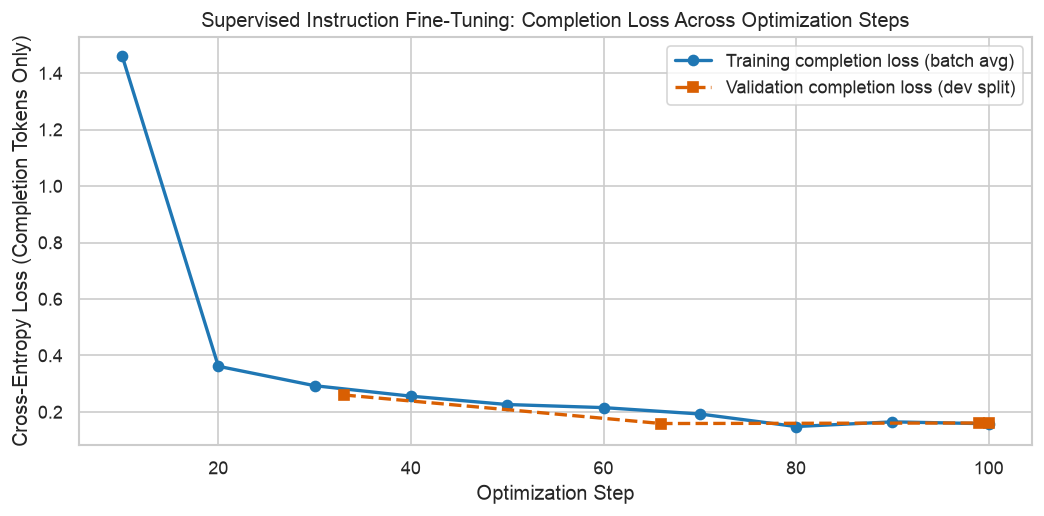

In [8]:
from germeval_llm.training import (
    run_sft_adapter_training,
    extract_training_and_eval_series,
)
from germeval_llm.reporting import plot_training_and_validation_loss

if RUN_LIVE_GPU:
    train_summary = run_sft_adapter_training(
        config_path=TRAIN_CONFIG,
        train_jsonl_path='data/derived/task_c/train.jsonl',
        dev_jsonl_path='data/derived/task_c/dev.jsonl',
        output_adapter_dir=ADAPTER_DIR,
        subset_size=TRAIN_SUBSET_SIZE,
        max_steps_override=MAX_TRAIN_STEPS,
        sampling_strategy='stratified',
        seed_override=SEED,
    )
    import torch; torch.cuda.empty_cache()
else:
    log_path = exp_manifest.get('training_log_file') or 'results/runs/classroom_fast_n1000_training_history.json'
    train_summary = json.loads(Path(log_path).read_text(encoding='utf-8'))

train_history, eval_history = extract_training_and_eval_series(train_summary.get('log_history', []))

print('TRAINING PROGRESS (Training Batches)')
print('─' * 48)
print(f'{"Step":>6}   {"Training loss":>15}   {"Learning rate":>15}')
for ev in train_history:
    print(f'{ev["step"]:6d}   {ev["loss"]:15.4f}   {ev["learning_rate"]:15.2e}')

if eval_history:
    print('\nVALIDATION PROGRESS (Held-out dev Split)')
    print('─' * 48)
    print(f'{"Step":>6}   {"Validation loss":>15}   {"Epoch":>15}')
    for ev in eval_history:
        print(f'{ev["step"]:6d}   {ev["eval_loss"]:15.4f}   {ev["epoch"]:15.2f}')

dur_sec = float(train_summary.get('train_wall_sec', 0.0))
mins, secs = divmod(int(round(dur_sec)), 60)
vram_gb = train_summary.get('peak_vram_mb', 0.0) / 1024.0
vram_str = f'{vram_gb:.2f} GB (measured CUDA)' if vram_gb > 0 else f'N/A (recorded on {train_summary.get("device", "mps").upper()})'
final_val_str = f'{eval_history[-1]["eval_loss"]:.4f}' if eval_history else 'N/A'

print('\nTRAINING COMPLETED')
print('─' * 48)
print(f'Optimization steps:       {train_summary["max_steps"]:,}')
print(f'Training examples:        {train_summary["train_examples"]:,}')
print(f'Trainable parameters:     {train_summary["trainable_parameters"] / 1e6:.2f}M ({100 * train_summary["trainable_parameters"] / train_summary["total_parameters"]:.2f}%)')
print(f'Training duration:        {mins}m {secs:02d}s ({train_summary.get("device", "unknown").upper()})')
print(f'Peak GPU memory:          {vram_str}')
print(f'Final training loss:      {train_summary["train_loss"]:.4f}')
print(f'Final validation loss:    {final_val_str}')
print(f'Adapter saved to:         {train_summary["adapter_dir"]}')

fig_loss = plot_training_and_validation_loss(train_history, eval_history)
plt.show()
plt.close(fig_loss)

- **Observation & Interpretation:** The loss curve shows how the model becomes better at predicting supervised completions across optimization steps, and the declining validation loss on `dev` confirms that completion prediction improves on unseen documents as well. However, a lower cross-entropy loss alone does not tell us whether improved token probabilities translate into valid JSON schemas or higher aspect F1. The final evaluation on `test_syn` will determine whether this optimization improves output validity and classification performance.

---
# Part IV — Quantitative Evaluation, Error Analysis, and Conclusions

## 9. Quantitative Evaluation

### Core Evaluation Metrics
We evaluate both models on the identical `test_syn` documents using three primary metrics:
1. **Output validity (`Valid JSON` & `Schema validity`):**
   - *Valid JSON (Exact):* Does the model emit a raw JSON object with no surrounding Markdown fences or commentary?
   - *Schema validity:* Does the output parse (with or without stripping Markdown fences) into `{"labels": [...]}` containing only permitted GermEval 2017 labels?
2. **Category micro-F1 (`Task C1`):** Does the model identify the correct aspect categories (`Zugfahrt`, `Service_und_Kundenbetreuung`, etc.), regardless of sentiment polarity?
3. **Category + sentiment micro-F1 (`Task C2`):** Does the model identify both the correct aspect categories and their exact sentiment polarities?

### Measuring Statistical Uncertainty (`Paired Bootstrap`)
To test whether observed F1 gains could be due to sampling noise on our evaluation set, we use **paired document-level bootstrap resampling** ($B = 1{,}000$ resamples): on each bootstrap draw, we sample evaluation document IDs with replacement and compute both models' F1 and their difference
$$
\Delta F_1 = F_{1,\text{fine-tuned}} - F_{1,\text{baseline}}
$$
on the exact same sampled documents.

BEFORE VS. AFTER COMPARISON (classroom_fast_n1000_seed42, n = 150 test_syn docs)


,Metric,Zero-shot,Fine-tuned,Change (Δ),95% Paired Bootstrap CI (Δ)
0,Valid JSON (exact raw output),0.0000,0.9867,+0.9867,—
1,Schema validity (incl. fenced),0.7133,0.9867,+0.2733,—
2,Category micro-F1 (Task C1),0.1608,0.6594,+0.4986,"[+0.4091, +0.5947]"
3,Category + sentiment micro-F1 (Task C2),0.1150,0.5468,+0.4317,"[+0.3407, +0.5196]"


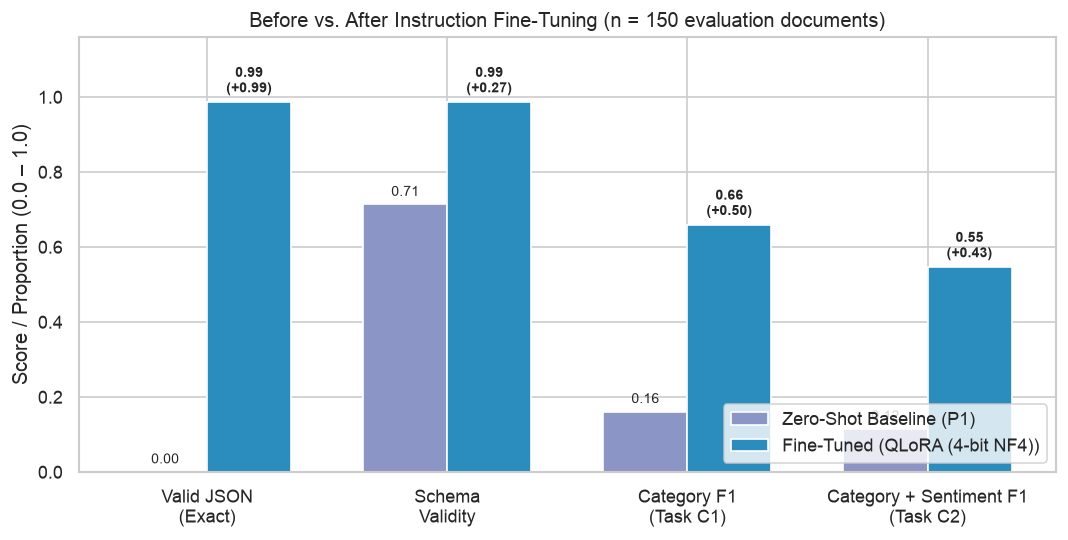


Secondary & Legacy Benchmark Metrics:


,Advanced / Secondary Metric,Zero-shot,Fine-tuned,Change (Δ)
0,Document-level exact-set accuracy,0.1333,0.5467,+0.4133
1,Official Java-compatible F1 (EvaluationScript....,0.0610,0.3762,+0.3152


In [9]:
from germeval_llm.evaluation import compare_task_c_models
from germeval_llm.reporting import plot_before_after_metrics_comparison

if RUN_LIVE_GPU:
    ft_model, tokenizer = load_gemma_model_and_tokenizer(
        model_id='google/gemma-2-2b-it',
        adapter_path=ADAPTER_DIR,
        load_in_4bit=USE_4BIT_QUANTIZATION,
    )
    ft_gen_fn = build_hf_generator_fn(ft_model, tokenizer, max_new_tokens=128)
    raw_ft_preds = run_task_c_inference_with_generator(
        eval_docs,
        run_id=f'colab_{METHOD_TAG}_r16',
        split='test_syn',
        generate_fn=ft_gen_fn,
        prompt_key='p1_guidelines',
    )
    save_predictions_jsonl(raw_ft_preds, FT_PRED_PATH)
    del ft_model
    import torch; torch.cuda.empty_cache()
else:
    raw_ft_preds = load_predictions_jsonl(exp_manifest['finetuned_prediction_file'])

ft_preds = align_predictions(eval_docs, raw_ft_preds, expected_split='test_syn')
comparison = compare_task_c_models(
    eval_docs,
    baseline_preds,
    ft_preds,
    expected_split='test_syn',
    apply_gold_typo_patches=True,
    n_bootstrap=1000,
    seed=SEED,
)

b_m = comparison['baseline']
q_m = comparison['finetuned']
d_m = comparison['deltas']
c1_ci = comparison['paired_bootstrap_c1']
c2_ci = comparison['paired_bootstrap_c2']

primary_df = pd.DataFrame([
    {
        'Metric': 'Valid JSON (exact raw output)',
        'Zero-shot': f'{b_m["valid_exact_rate"]:.4f}',
        'Fine-tuned': f'{q_m["valid_exact_rate"]:.4f}',
        'Change (Δ)': f'{d_m["valid_exact_rate"]:+.4f}',
        '95% Paired Bootstrap CI (Δ)': '—',
    },
    {
        'Metric': 'Schema validity (incl. fenced)',
        'Zero-shot': f'{b_m["schema_validity_rate"]:.4f}',
        'Fine-tuned': f'{q_m["schema_validity_rate"]:.4f}',
        'Change (Δ)': f'{d_m["schema_validity_rate"]:+.4f}',
        '95% Paired Bootstrap CI (Δ)': '—',
    },
    {
        'Metric': 'Category micro-F1 (Task C1)',
        'Zero-shot': f'{b_m["task_c1_category_strict"]["micro_f1"]:.4f}',
        'Fine-tuned': f'{q_m["task_c1_category_strict"]["micro_f1"]:.4f}',
        'Change (Δ)': f'{d_m["c1_strict_micro_f1"]:+.4f}',
        '95% Paired Bootstrap CI (Δ)': f'[{c1_ci["delta_ci95_low"]:+.4f}, {c1_ci["delta_ci95_high"]:+.4f}]',
    },
    {
        'Metric': 'Category + sentiment micro-F1 (Task C2)',
        'Zero-shot': f'{b_m["task_c2_category_sentiment_strict"]["micro_f1"]:.4f}',
        'Fine-tuned': f'{q_m["task_c2_category_sentiment_strict"]["micro_f1"]:.4f}',
        'Change (Δ)': f'{d_m["c2_strict_micro_f1"]:+.4f}',
        '95% Paired Bootstrap CI (Δ)': f'[{c2_ci["delta_ci95_low"]:+.4f}, {c2_ci["delta_ci95_high"]:+.4f}]',
    },
])
print(f'BEFORE VS. AFTER COMPARISON ({exp_manifest["experiment_id"]}, n = {len(eval_docs)} test_syn docs)')
display(primary_df)

fig_comp = plot_before_after_metrics_comparison(comparison, method_label=METHOD_LABEL)
plt.show()
plt.close(fig_comp)

# Advanced / Secondary Metrics (Document Exact-Set Match & Official Java-Compatible Evaluator)
adv_df = pd.DataFrame([
    {
        'Advanced / Secondary Metric': 'Document-level exact-set accuracy',
        'Zero-shot': f'{b_m["task_c2_category_sentiment_strict"]["exact_set_accuracy"]:.4f}',
        'Fine-tuned': f'{q_m["task_c2_category_sentiment_strict"]["exact_set_accuracy"]:.4f}',
        'Change (Δ)': f'{d_m["exact_set_accuracy"]:+.4f}',
    },
    {
        'Advanced / Secondary Metric': 'Official Java-compatible F1 (EvaluationScript.jar)',
        'Zero-shot': f'{b_m["task_c2_category_sentiment_java_compat"]["micro_f1"]:.4f}',
        'Fine-tuned': f'{q_m["task_c2_category_sentiment_java_compat"]["micro_f1"]:.4f}',
        'Change (Δ)': f'{d_m["c2_java_compat_micro_f1"]:+.4f}',
    },
])
print('\nSecondary & Legacy Benchmark Metrics:')
display(adv_df)

### Questions for Discussion
- **Does fine-tuning improve classification performance?** Examine both the point estimate $\Delta F_1$ and the 95% paired bootstrap confidence interval.
- **Does it also improve output-format compliance?** Compare `Valid JSON (exact)` against `Schema validity (incl. fenced)`: why was `Schema validity` already high in the baseline while `Valid JSON (exact)` was near zero?
- **Which improvement is larger—output formatting or semantic classification?**
- **Can we conclude that the model has learned to generalize to all rail feedback?** What does the width of the 150-document confidence interval tell us about small evaluation slices?

---
## 10. Qualitative Error Analysis

- **Concept:** Aggregate F1 scores summarize corpus-level precision and recall across all label occurrences, but they do not show what changed on individual documents. For document-level qualitative analysis, we define exact-match correctness as:
$$
\operatorname{correct}(d) = \mathbb{1}\left[\hat{Y}_d = Y_d\right]
$$
where $Y_d$ is the set of gold `Category:polarity` pairs for document $d$. Notice that a multi-label prediction can be *partially* correct (matching one gold label while missing another, thus contributing a true positive to corpus micro-F1) while still failing document-level exact match.

Rather than printing the first five documents arbitrarily, we deterministically select one example for each of **five diagnostic archetypes** (reporting `UNAVAILABLE` if an archetype does not occur in the current evaluation slice):
1. **Baseline error corrected (`0-shot ❌ → Fine-tuned ✅`)**
2. **Both models correct (`0-shot ✅ → Fine-tuned ✅`)**
3. **Both models fail (`0-shot ❌ → Fine-tuned ❌`)**
4. **Fine-tuning introduces an error (`0-shot ✅ → Fine-tuned ❌`)**
5. **Output-format or schema problem (`Format/Schema issue → Exact JSON`)**

In [10]:
from germeval_llm.reporting import select_pedagogical_error_analysis_examples
from germeval_llm.schemas import ChatMessage

diag_rows = select_pedagogical_error_analysis_examples(
    eval_docs,
    baseline_preds,
    ft_preds,
    apply_gold_typo_patches=True,
)

print('A. FIVE DIAGNOSTIC ARCHETYPES ACROSS THE EVALUATION SLICE')
print('─' * 72)
table_view = []
for r in diag_rows:
    table_view.append({
        'Diagnostic Archetype': r['archetype'],
        'Input (German Text)': r['input_text'][:110] + ('...' if len(r['input_text']) > 110 else ''),
        'Gold Labels': r['gold_labels'],
        'Zero-Shot Prediction': r['zero_shot_prediction'],
        'Fine-Tuned Prediction': r['finetuned_prediction'],
        'Zero-Shot Correct?': r['zero_shot_correct'],
        'Fine-Tuned Correct?': r['finetuned_correct'],
        'Zero-Shot Format': r['zero_shot_format'],
    })
display(pd.DataFrame(table_view))

# B. Side-by-Side Prompt & Response Showcase (Same Evaluation Prompt, Before vs. After Training)
showcase_case = diag_rows[0] if diag_rows[0]['available'] else diag_rows[4]
if showcase_case['available']:
    eval_user_prompt = render_task_c_user_prompt(showcase_case['input_text'], prompt_key='p1_guidelines')
    eval_gemma_prompt = format_gemma_chat_string(
        [ChatMessage(role='user', content=eval_user_prompt)],
        completion_messages=None,
        include_bos=True,
    )
    print(f'\nB. SIDE-BY-SIDE PROMPT & RESPONSE COMPARISON — {showcase_case["archetype"]}')
    print('─' * 72)
    print(f'Document ID: {showcase_case["doc_id"]}')
    print(f'Gold Labels: {showcase_case["gold_labels"]}\n')

    zs_err_str = '; '.join(showcase_case['zero_shot_errors']) if showcase_case['zero_shot_errors'] else 'None'
    ft_err_str = '; '.join(showcase_case['finetuned_errors']) if showcase_case['finetuned_errors'] else 'None'
    prompt_summary = (
        f'Identical P1_guidelines prompt ({len(eval_gemma_prompt):,} chars): '
        '<bos><start_of_turn>user\\nDu bist ein Experte ... [19 Kategorien & 4 Regeln] ... '
        'Text:\\n...<end_of_turn>\\n<start_of_turn>model\\n'
    )
    side_by_side_df = pd.DataFrame([
        {
            'Stage': 'Input',
            'Zero-shot model': showcase_case['input_text'],
            'Fine-tuned model': showcase_case['input_text'],
        },
        {
            'Stage': 'Instructions',
            'Zero-shot model': prompt_summary,
            'Fine-tuned model': prompt_summary,
        },
        {
            'Stage': 'Output (Raw model completion)',
            'Zero-shot model': repr(showcase_case['zero_shot_raw']),
            'Fine-tuned model': repr(showcase_case['finetuned_raw']),
        },
        {
            'Stage': 'Evaluation (Parsed labels & errors)',
            'Zero-shot model': (
                f"Parsed: {showcase_case['zero_shot_prediction']} | "
                f"Format: {showcase_case['zero_shot_format']} | "
                f"Errors: {zs_err_str} | "
                f"Exact match: {showcase_case['zero_shot_correct']}"
            ),
            'Fine-tuned model': (
                f"Parsed: {showcase_case['finetuned_prediction']} | "
                f"Format: {showcase_case['finetuned_format']} | "
                f"Errors: {ft_err_str} | "
                f"Exact match: {showcase_case['finetuned_correct']}"
            ),
        },
    ])
    display(side_by_side_df)

    eval_details_html = f'''
    <details style="margin: 10px 0; padding: 8px 12px; border: 1px solid #cbd5e1; border-radius: 6px; background: #f8fafc;">
      <summary style="cursor: pointer; font-weight: 600; color: #1e293b;">
        🔍 Expand to inspect the full evaluation prompt sent identically to both models (doc_id={html.escape(showcase_case['doc_id'])})
      </summary>
      <pre style="margin-top: 8px; white-space: pre-wrap; font-size: 12px; line-height: 1.4; color: #0f172a;">{html.escape(eval_gemma_prompt)}</pre>
    </details>
    '''
    display(HTML(eval_details_html))

# C. Show raw string comparison for Archetype 5 (Format / Schema Compliance)
fmt_case = diag_rows[4]
if fmt_case['available']:
    print('\nC. RAW OUTPUT INSPECTION — Archetype 5 (Format / Schema Compliance):')
    print('─' * 72)
    print(f'Document ID:         {fmt_case["doc_id"]}')
    print(f'Zero-Shot Status:    {fmt_case["zero_shot_format"]}')
    print(f'Zero-Shot Raw:       {fmt_case["zero_shot_raw"]!r}')
    print(f'Fine-Tuned Status:   {fmt_case["finetuned_format"]}')
    print(f'Fine-Tuned Raw:      {fmt_case["finetuned_raw"]!r}')

A. FIVE DIAGNOSTIC ARCHETYPES ACROSS THE EVALUATION SLICE
────────────────────────────────────────────────────────────────────────


,Diagnostic Archetype,Input (German Text),Gold Labels,Zero-Shot Prediction,Fine-Tuned Prediction,Zero-Shot Correct?,Fine-Tuned Correct?,Zero-Shot Format
0,1. Baseline error corrected,Unwetter-Bilanz: 65.255 Blitze in 24 Stunden ü...,[Sonstige_Unregelmässigkeiten:negative],"[Sicherheit:negative, Sonstige_Unregelmässigke...",[Sonstige_Unregelmässigkeiten:negative],No (partial: 1/1 gold matched),Yes (exact match),VALID_FENCED (Markdown-fenced JSON (recoverable))
1,2. Both models correct,RT @DB_Info: Stellwerksstörung in #Köln Hbf ht...,[Sonstige_Unregelmässigkeiten:negative],[Sonstige_Unregelmässigkeiten:negative],[Sonstige_Unregelmässigkeiten:negative],Yes (exact match),Yes (exact match),VALID_FENCED (Markdown-fenced JSON (recoverable))
2,3. Both models fail,screams @ deutsche bahn.,[Allgemein:neutral],[Image:negative],[Allgemein:negative],No,No,VALID_FENCED (Markdown-fenced JSON (recoverable))
3,4. Fine-tuning introduces error,Wohnmobilurlauber steuern am liebsten deutsche...,[],[],[Allgemein:neutral],Yes (exact match),No,VALID_FENCED (Markdown-fenced JSON (recoverable))
4,5. Output-format / schema problem,Re: Mario Barth Da sollte sich unsere Bahn mal...,[Allgemein:neutral],[],[Allgemein:negative],No,No,INVALID_SCHEMA (Schema violation (missing/non-...



B. SIDE-BY-SIDE PROMPT & RESPONSE COMPARISON — 1. Baseline error corrected
────────────────────────────────────────────────────────────────────────
Document ID: http://www.msn.com/de-de/wetter/topgeschichten/unwetter-bilanz-65255-blitze-in-24-stunden-%c3%bcber-nrw/ar-AAcBBsA
Gold Labels: ['Sonstige_Unregelmässigkeiten:negative']



,Stage,Zero-shot model,Fine-tuned model
0,Input,Unwetter-Bilanz: 65.255 Blitze in 24 Stunden ü...,Unwetter-Bilanz: 65.255 Blitze in 24 Stunden ü...
1,Instructions,"Identical P1_guidelines prompt (3,456 chars): ...","Identical P1_guidelines prompt (3,456 chars): ..."
2,Output (Raw model completion),"'```json\n{""labels"": [\n ""Sonstige_Unregelmäs...","'{""labels"":[""Sonstige_Unregelmässigkeiten:nega..."
3,Evaluation (Parsed labels & errors),"Parsed: ['Sicherheit:negative', 'Sonstige_Unre...",Parsed: ['Sonstige_Unregelmässigkeiten:negativ...



C. RAW OUTPUT INSPECTION — Archetype 5 (Format / Schema Compliance):
────────────────────────────────────────────────────────────────────────
Document ID:         http://www.facebook.com/125797237471539/posts/1062979770419943?comment\_id=1063381477046439#125797237471539\_1062979770419943\_1063381477046439
Zero-Shot Status:    INVALID_SCHEMA (Schema violation (missing/non-list 'labels'))
Zero-Shot Raw:       '```json\n{"labels": [\n  {"Kategorie": "Image", "Polarität": "negative"},\n  {"Kategorie": "Service_und_Kundenbetreuung", "Polarität": "negative"}\n]}\n```'
Fine-Tuned Status:   VALID_EXACT (Exact JSON object)
Fine-Tuned Raw:      '{"labels":["Allgemein:negative"]}'


- **Observation & Interpretation:**
  - **Same instructions, changed behavior (Table B):** Both models receive the exact same `P1_guidelines` prompt and German document (`<bos><start_of_turn>user ... <end_of_turn>\n<start_of_turn>model\n`). What changes after supervised fine-tuning is the model's mapping from that conditioning context to the generated completion—eliminating Markdown wrappers/schema violations and aligning category predictions with GermEval annotation boundaries.
  - **Archetype 1 vs. Archetype 4:** Supervised fine-tuning corrects many zero-shot errors (especially false positives on irrelevant tweets and missed rail categories), but **Archetype 4** demonstrates that fine-tuning is not monotonic—shifting decision boundaries statistically can occasionally introduce errors on examples the baseline got right.
  - **Archetype 3:** Hard multi-aspect or implicit-opinion documents remain challenging for both models, motivating larger training sets (`full_l4`) or richer context.
  - **Archetype 5:** Fine-tuning eliminates the Markdown code-fence wrapper and schema errors (`INVALID_SCHEMA` / `VALID_FENCED` → `VALID_EXACT`), producing clean machine-readable JSON without post-processing.

---
## 11. Conclusions and Limitations

### Summary of Evidence Along the Learning Objectives
1. **Zero-shot inference vs. supervised instruction fine-tuning:** Zero-shot prompting relies on pretrained instruction-following priors and verbal guidelines; supervised fine-tuning adapts model parameters directly on task-specific examples.
2. **From labeled examples to instruction–completion pairs:** Structured annotations are serialized into a deterministic user prompt and a target assistant JSON completion.
3. **Completion-only loss masking (`-100`):** Completion-only masking restricts the supervised prediction targets to the assistant completion, while preserving the prompt as conditioning context attended to during generation.
4. **Instruction fine-tuning vs. LoRA and QLoRA:** The behavioral gains in JSON formatting and aspect classification come from **supervised instruction fine-tuning** on labeled examples; **LoRA** (updating 0.79% of parameters via low-rank adapters) and **QLoRA** (quantizing frozen base weights to 4-bit `NF4`) are the efficiency mechanisms that make this optimization feasible on a single GPU.
5. **Quantitative & qualitative evaluation:** Paired evaluation confirms substantial gains in exact JSON compliance, Category micro-F1 (`Task C1`), and Category+Sentiment micro-F1 (`Task C2`), while qualitative archetype analysis reveals both corrected errors and occasional regressions.

### Experimental Limitations
- **Demonstration scale vs. full training:** The classroom configuration (`N = 1,000` training examples, `100` steps, `150` evaluation documents) optimizes execution time for a live session. As shown by the paired bootstrap confidence intervals in Section 9, a 150-document evaluation slice carries wider statistical uncertainty than the full 2,566-document `test_syn` benchmark (`DEMO_MODE = 'full_l4'`).
- **Validation vs. held-out test discipline:** In a rigorous research workflow, all prompt templates, adapter ranks, and learning rates must be selected exclusively on `dev` before evaluating once on the held-out test set.
- **Temporal generalization (`test_syn` vs. `test_dia`):** Improving performance on synchronic test data (`test_syn`) does not guarantee identical performance when topic distributions shift over time (such as winter service disruptions in `test_dia`).